In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("PhishFOE_ds.csv", header=0)

Saving PhishFOE_ds.csv to PhishFOE_ds.csv


PHISHING DETECTION AVEC LIGHTGBM - ANALYSE AMÉLIORÉE ANTI-OVERFITTING
Dimensions du dataset: 101063 lignes × 32 colonnes


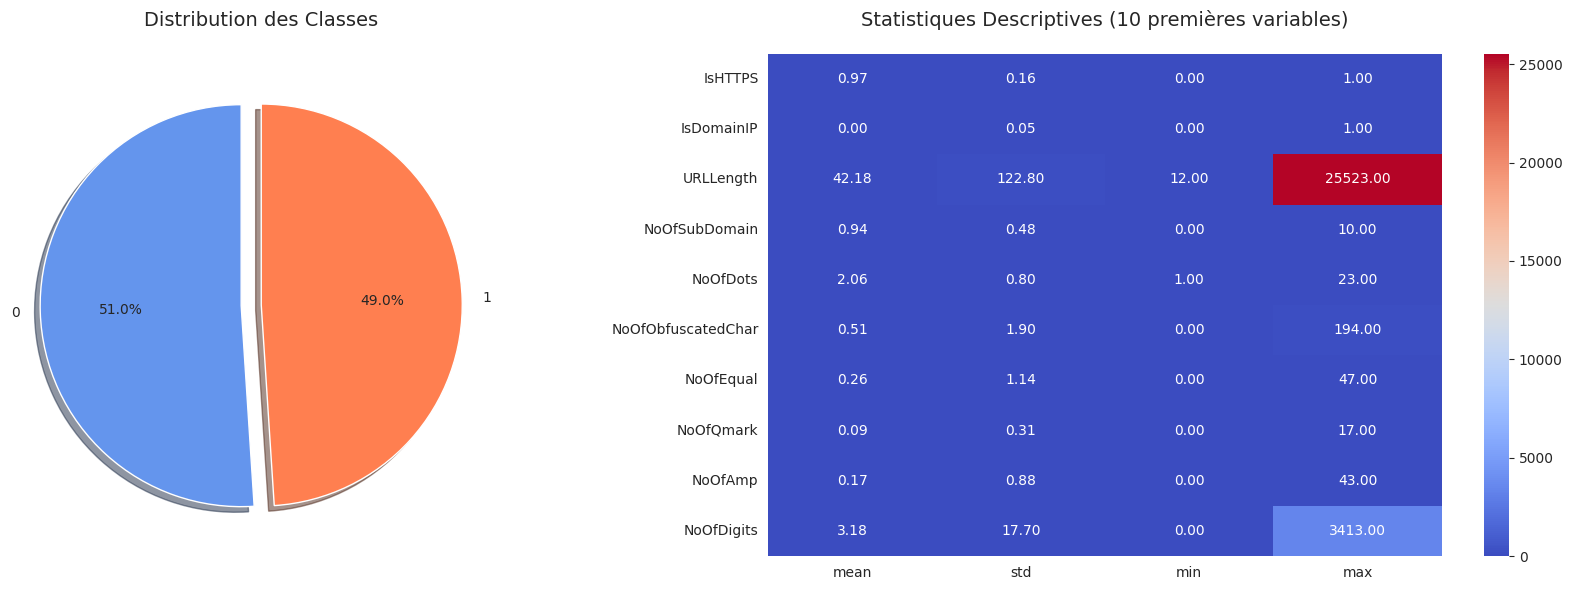


DIVISION INITIALE ET PRÉTRAITEMENT DES DONNÉES

Valeurs manquantes par colonne:
Aucune valeur manquante

Distribution des classes dans les données complètes: [51572 49491]
Distribution des classes dans l'ensemble de test final: [7736 7424]
Distribution des classes dans l'ensemble d'entraînement+validation: [43836 42067]


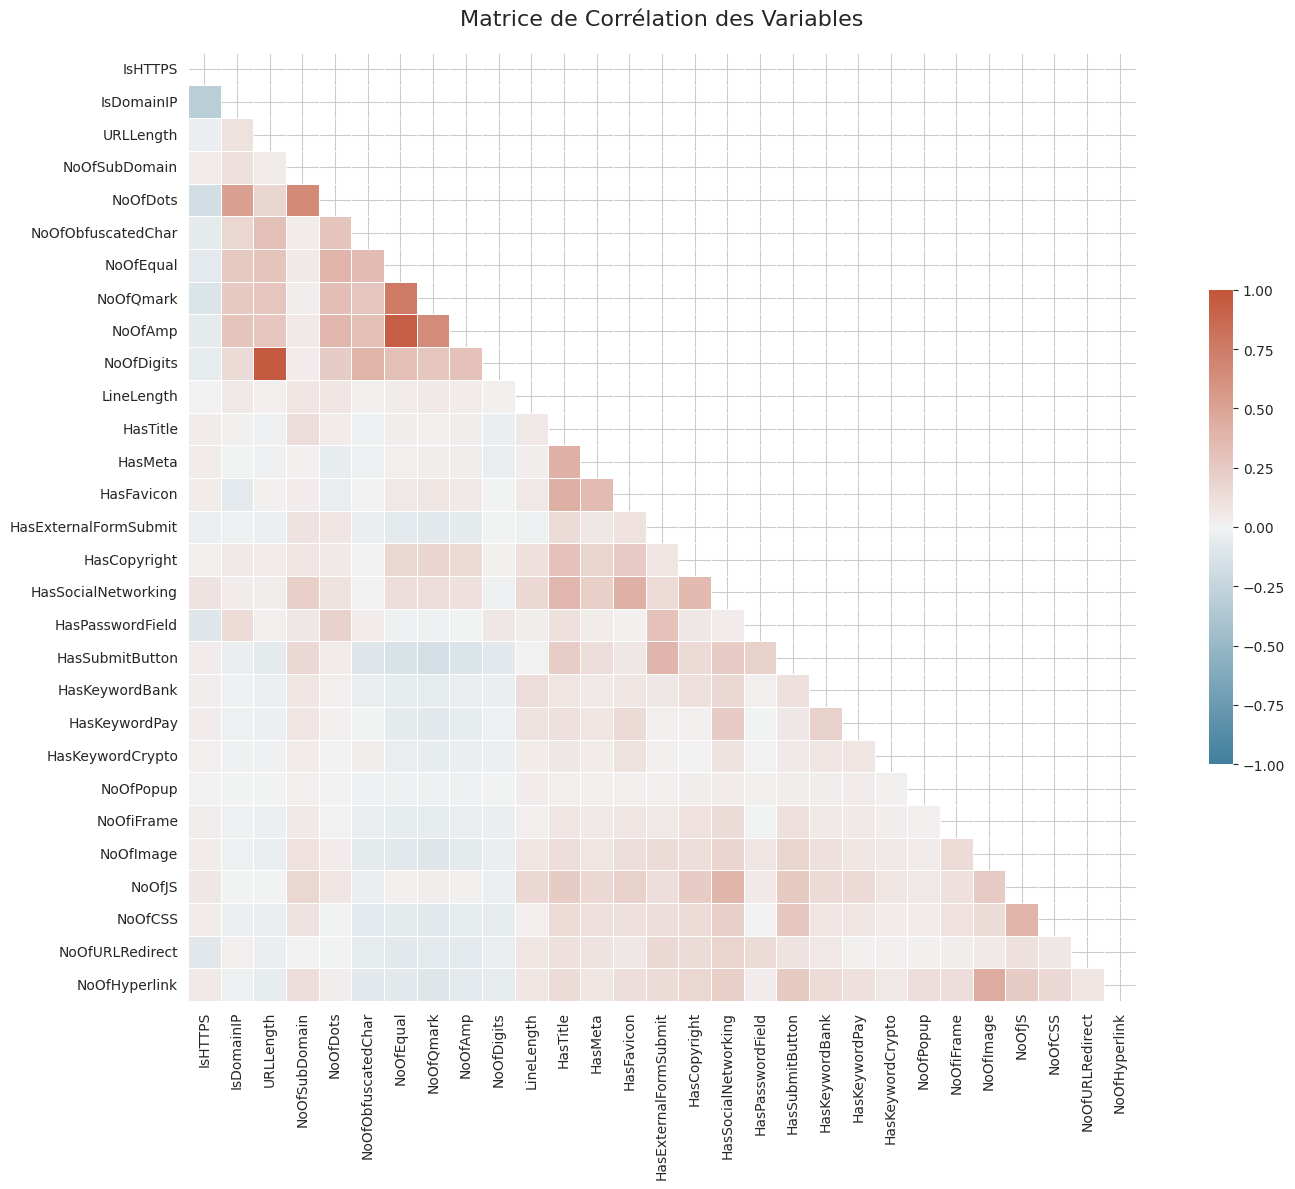


DÉTECTION D'ANOMALIES ET PRÉTRAITEMENT
[LightGBM] [Info] Number of positive: 33095, number of negative: 34939
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016767 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1718
[LightGBM] [Info] Number of data points in the train set: 68034, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.486448 -> initscore=-0.054221
[LightGBM] [Info] Start training from score -0.054221
[LightGBM] [Info] Number of positive: 33095, number of negative: 34939
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015970 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1725
[LightGBM] [Info] Number of data points in the train set: 68034, number

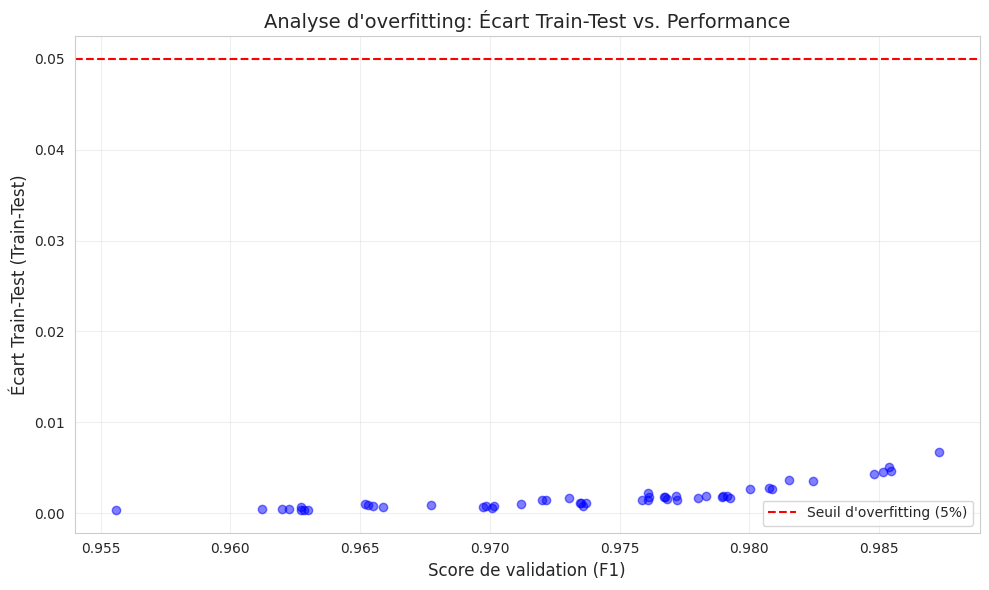


Paramètres équilibrés avec faible overfitting: {'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 100, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

ENTRAÎNEMENT DU MODÈLE FINAL AVEC EARLY STOPPING

Entraînement du modèle final avec early stopping...
Training until validation scores don't improve for 30 rounds
[20]	training's binary_logloss: 0.147034	training's auc: 0.995749	valid_1's binary_logloss: 0.144452	valid_1's auc: 0.995997
[40]	training's binary_logloss: 0.08023	training's auc: 0.996968	valid_1's binary_logloss: 0.0784195	valid_1's auc: 0.997032
[60]	training's binary_logloss: 0.0613362	training's auc: 0.997819	valid_1's binary_logloss: 0.0622195	valid_1's auc: 0.997537
[80]	training's binary_logloss: 0.0526553	training's auc: 0.9983	valid_1's binary_logloss: 0.0551543	valid_1's auc: 0.997859
[100]	training's binary_logloss: 0.04638	training's auc: 0.998676	valid_1's binary_logloss: 0.0508063	

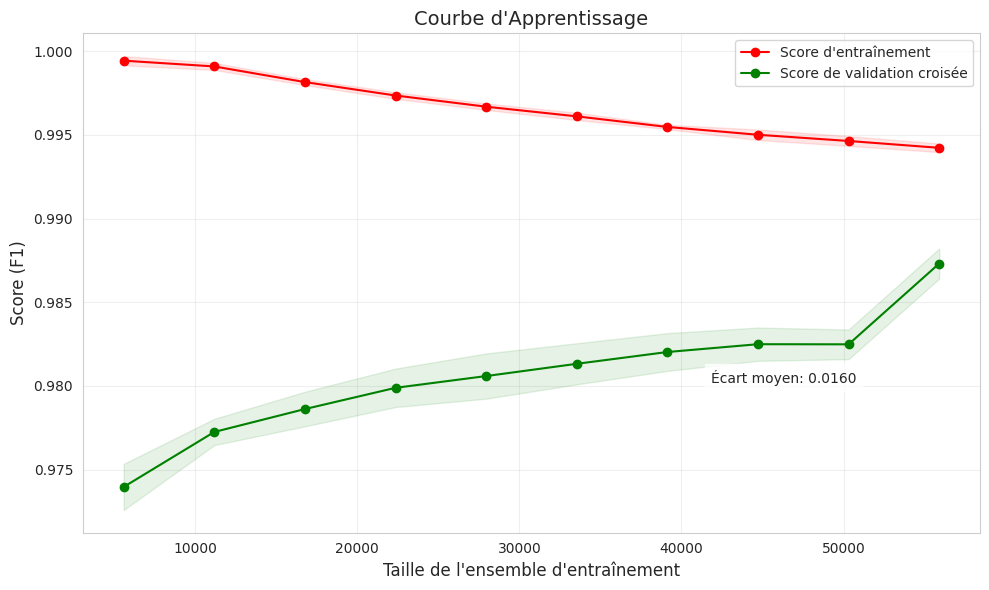

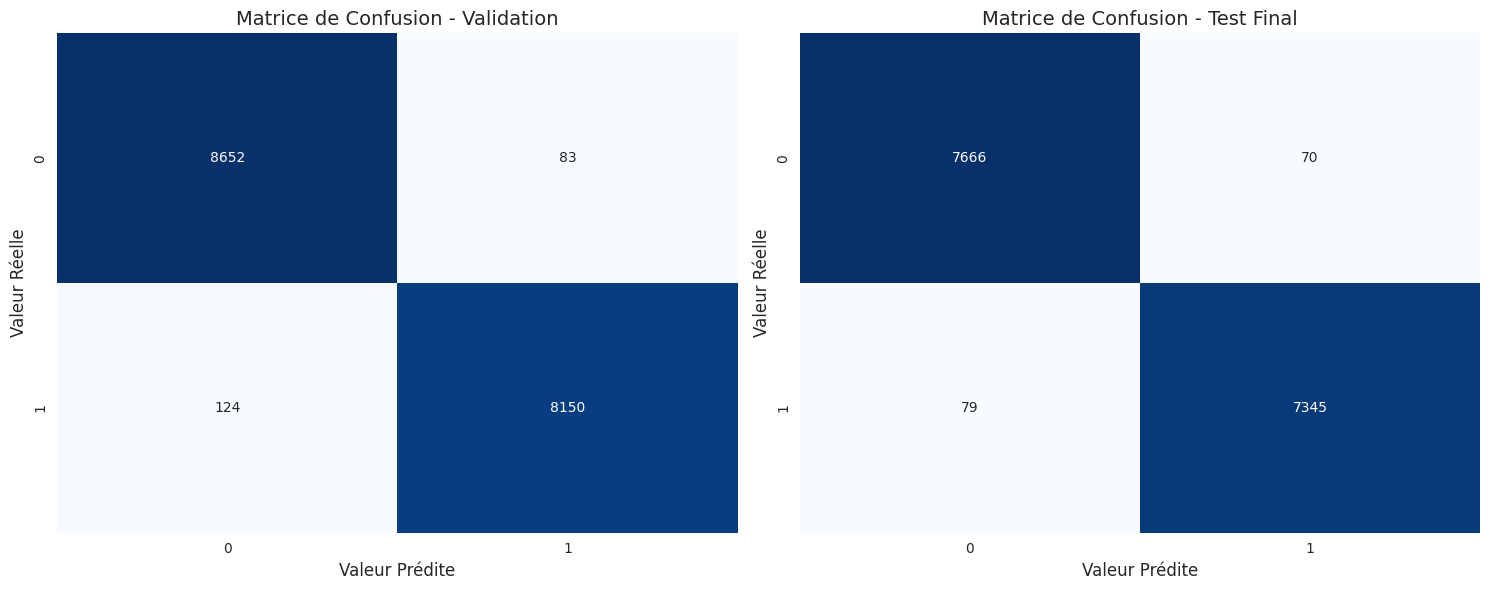

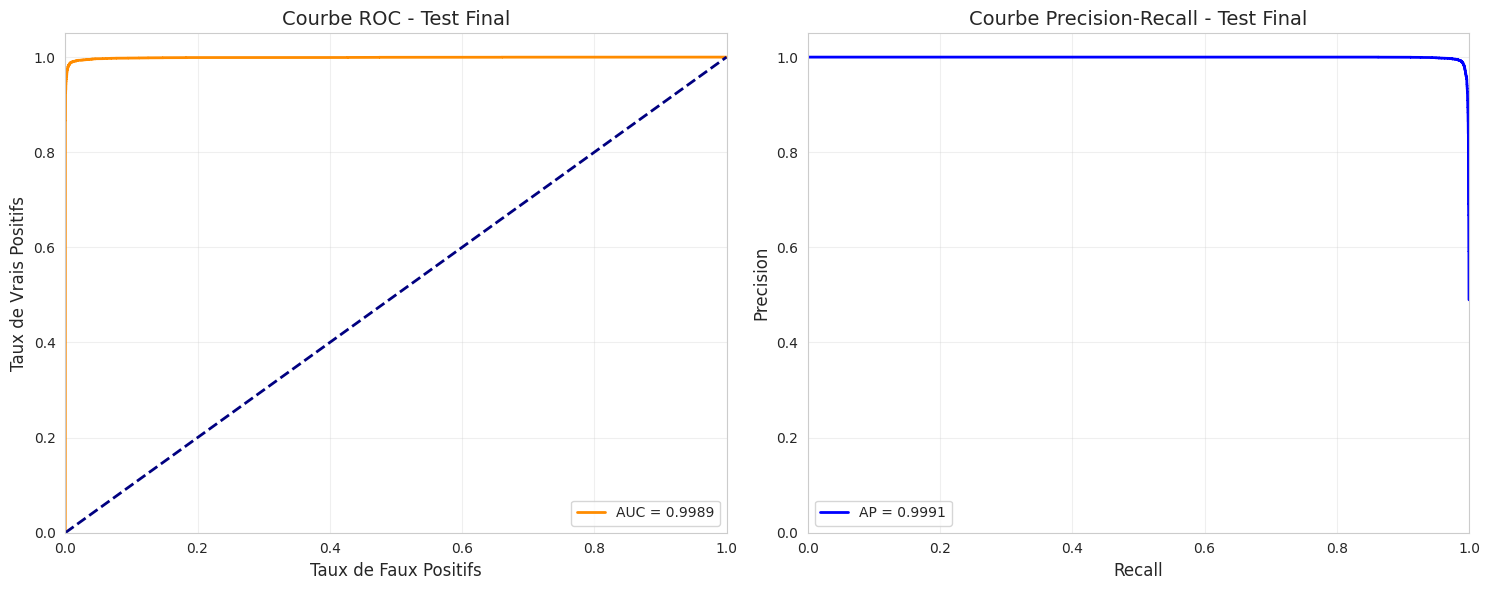


RÉCAPITULATIF ET VÉRIFICATION ANTI-OVERFITTING

Résumé des performances:
           Métrique  Valeur
0    Accuracy - Val  0.9878
1   Accuracy - Test  0.9902
2   Precision - Val  0.9899
3  Precision - Test  0.9906
4      Recall - Val  0.9850
5     Recall - Test  0.9894
6          F1 - Val  0.9875
7         F1 - Test  0.9900
8        AUC - Test  0.9989

Vérification finale d'overfitting:
Écart F1 (Val vs Test): 0.0025 (✅ OK)
Écart Accuracy (Val vs Test): 0.0023 (✅ OK)
Écart Precision (Val vs Test): 0.0006 (✅ OK)
Écart Recall (Val vs Test): 0.0043 (✅ OK)

✅ VALIDATION: Le modèle ne présente pas de signes importants d'overfitting.

Sauvegarde du modèle et des préprocesseurs...
Modèle sauvegardé sous 'lightgbm_phishing_model_robuste.pkl'

ANALYSE TERMINÉE


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.model_selection import cross_val_score, cross_validate, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score, precision_recall_curve
from sklearn.metrics import confusion_matrix, average_precision_score, f1_score
from sklearn.metrics import precision_score, recall_score, make_scorer, matthews_corrcoef
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Set display precision & style
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)
sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-pastel')

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
print("="*80)
print("PHISHING DETECTION AVEC LIGHTGBM - ANALYSE AMÉLIORÉE ANTI-OVERFITTING")
print("="*80)

# Assurez-vous que df est défini
# df = pd.read_csv('votre_dataset.csv')  # Décommentez cette ligne et spécifiez le chemin

print(f"Dimensions du dataset: {df.shape[0]} lignes × {df.shape[1]} colonnes")

# Créer une figure avec deux subplots pour l'exploration initiale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Afficher la distribution des classes
target_column = 'label' if 'label' in df.columns else 'label'
class_counts = df[target_column].value_counts()
colors = ['#6495ED', '#FF7F50']
ax1.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%',
        colors=colors, shadow=True, startangle=90, explode=(0.1, 0))
ax1.set_title('Distribution des Classes', fontsize=14, pad=20)

# Afficher les statistiques descriptives pour quelques colonnes numériques
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns[:10]
stats_df = df[numeric_columns].describe().T[['mean', 'std', 'min', 'max']]
sns.heatmap(stats_df, cmap='coolwarm', annot=True, fmt='.2f', ax=ax2)
ax2.set_title('Statistiques Descriptives (10 premières variables)', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

# ---------------------------
# 1. PRÉPARATION: Division initiale du dataset avec stratification
# ---------------------------
# AMÉLIORATION: Diviser les données AVANT tout prétraitement pour avoir un jeu de validation final non biaisé
print("\n" + "="*80)
print("DIVISION INITIALE ET PRÉTRAITEMENT DES DONNÉES")
print("="*80)

# Retirer les colonnes non pertinentes
for col in ['URL']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

# Vérification et traitement des valeurs manquantes
missing_values = df.isnull().sum()
print("\nValeurs manquantes par colonne:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Aucune valeur manquante")

# Suppression des observations avec une valeur manquante dans la target (si nécessaire)
df.dropna(subset=[target_column], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=[target_column])
y = df[target_column]
feature_names = X.columns

# AMÉLIORATION: Création d'un ensemble de test complètement indépendant
# pour évaluation finale avec stratification de classe
X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

print(f"\nDistribution des classes dans les données complètes: {np.bincount(y)}")
print(f"Distribution des classes dans l'ensemble de test final: {np.bincount(y_test_final)}")
print(f"Distribution des classes dans l'ensemble d'entraînement+validation: {np.bincount(y_train_val)}")

# Vérifier les corrélations entre les variables
plt.figure(figsize=(16, 12))
corr_matrix = X_train_val.corr()
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, annot=False, cbar_kws={'shrink': .5})
plt.title('Matrice de Corrélation des Variables', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# ---------------------------
# 2. Détection d'anomalies avec Isolation Forest AMÉLIORÉE
# ---------------------------
print("\n" + "="*80)
print("DÉTECTION D'ANOMALIES ET PRÉTRAITEMENT")
print("="*80)

# AMÉLIORATION: Utiliser CV pour déterminer la meilleure contamination
contamination_range = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1]
iso_results = []

for cont in contamination_range:
    iso = IsolationForest(contamination=cont, random_state=42, n_jobs=-1)
    pred_anomalies = iso.fit_predict(X_train_val)
    mask = pred_anomalies != -1
    X_clean = X_train_val[mask]
    y_clean = y_train_val[mask]

    # Évaluation rapide avec CV sur les données nettoyées
    cv_scores = cross_val_score(
        lgb.LGBMClassifier(random_state=42, n_jobs=-1),
        X_clean, y_clean,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='f1'
    )

    iso_results.append((cont, np.mean(cv_scores), 1 - np.sum(mask) / len(mask)))

# Afficher les résultats
iso_df = pd.DataFrame(iso_results, columns=['Contamination', 'F1 Score', 'Proportion Anomalies'])
print("\nRésultats de la détection d'anomalies avec différents taux de contamination:")
print(iso_df)

# Choisir la meilleure contamination en fonction du F1 score
best_contamination = iso_df.loc[iso_df['F1 Score'].idxmax(), 'Contamination']
print(f"\nMeilleure contamination: {best_contamination}")

# Appliquer la meilleure détection d'anomalies
iso = IsolationForest(contamination=best_contamination, random_state=42, n_jobs=-1)
pred_anomalies = iso.fit_predict(X_train_val)
mask = pred_anomalies != -1
X_clean = X_train_val[mask]
y_clean = y_train_val[mask]

nombre_anomalies = len(X_train_val) - np.sum(mask)
print(f"Points supprimés comme anomalies: {nombre_anomalies} ({nombre_anomalies/len(X_train_val)*100:.2f}%)")

# ---------------------------
# 3. AMÉLIORATION MAJEURE: Pipeline d'entraînement robuste
# ---------------------------
print("\n" + "="*80)
print("PIPELINE DE PRÉTRAITEMENT ET MODÉLISATION")
print("="*80)

# Division des données nettoyées en ensembles d'entraînement et de validation
X_train, X_val, y_train, y_val = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

print("\nDistribution après nettoyage et séparation:")
print(f"Ensemble d'entraînement: {np.bincount(y_train)}")
print(f"Ensemble de validation: {np.bincount(y_val)}")

# AMÉLIORATION: Création d'un pipeline complet avec prétraitement et SMOTE
# qui garantit que SMOTE est appliqué UNIQUEMENT aux données d'entraînement
preprocessing_pipeline = Pipeline([
    ('power_transform', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Appliquer le prétraitement à toutes les données
X_train_preprocessed = preprocessing_pipeline.fit_transform(X_train)
X_val_preprocessed = preprocessing_pipeline.transform(X_val)
X_test_final_preprocessed = preprocessing_pipeline.transform(X_test_final)

# AMÉLIORATION: Utiliser BorderlineSMOTE pour un rééquilibrage plus précis
print("\nRééquilibrage des classes avec BorderlineSMOTE (plus conservateur)...")
smote = BorderlineSMOTE(random_state=42, k_neighbors=5, m_neighbors=10)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_preprocessed, y_train)

print(f"Distribution après rééquilibrage: {np.bincount(y_train_resampled)}")

# ---------------------------
# 4. SÉLECTION DE CARACTÉRISTIQUES AMÉLIORÉE
# ---------------------------
print("\n" + "="*80)
print("SÉLECTION DE CARACTÉRISTIQUES AVEC RFECV ET VALIDATION CROISÉE NESTED")
print("="*80)

# AMÉLIORATION: Configuration RFECV avec CV imbriquée pour éviter le biais
base_lgbm = lgb.LGBMClassifier(
    random_state=42,
    n_jobs=-1,
    # Paramètres par défaut plus conservateurs pour limiter l'overfitting
    reg_alpha=0.1,
    reg_lambda=0.1,
    max_depth=5,
    num_leaves=31
)

# Configuration RFECV plus robuste
rfecv = RFECV(
    estimator=base_lgbm,
    step=1,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),  # CV répétée pour plus de robustesse
    scoring='f1',
    n_jobs=-1,
    verbose=1,
    min_features_to_select=5
)

print("\nExécution de la sélection de features avec RFECV...")
rfecv.fit(X_train_resampled, y_train_resampled)

# Résultats RFECV
print(f"\nNombre optimal de features: {rfecv.n_features_}")
print(f"Score avec {rfecv.n_features_} features: {rfecv.cv_results_['mean_test_score'][rfecv.n_features_ - 1]:.4f}")

# Récupérer les features sélectionnées
selected_features_mask = rfecv.support_
selected_feature_names = feature_names[selected_features_mask]

# Afficher les features sélectionnées
print("\nFeatures sélectionnées par RFECV:")
for i, feature in enumerate(selected_feature_names):
    print(f"{i+1}. {feature}")

# Transformer les données pour garder uniquement les features sélectionnées
X_train_selected = rfecv.transform(X_train_resampled)
X_val_selected = rfecv.transform(X_val_preprocessed)
X_test_final_selected = rfecv.transform(X_test_final_preprocessed)

# ---------------------------
# 5. RECHERCHE D'HYPERPARAMÈTRES AMÉLIORÉE
# ---------------------------
print("\n" + "="*80)
print("RECHERCHE D'HYPERPARAMÈTRES AVEC VALIDATION CROISÉE STRATIFIÉE")
print("="*80)

# AMÉLIORATION: Définir des métriques multiples pour évaluer différents aspects
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'f1': make_scorer(f1_score),
    'mcc': make_scorer(matthews_corrcoef)  # Matthews Correlation Coefficient, bon pour les classes déséquilibrées
}

# AMÉLIORATION: Paramètres plus conservateurs pour éviter l'overfitting
param_grid = {
    'num_leaves': [15, 31, 50],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'min_child_samples': [50, 100, 200],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_alpha': [0.1, 0.5, 1.0],
    'reg_lambda': [0.1, 0.5, 1.0]
}

lgbm_model = lgb.LGBMClassifier(random_state=42, objective='binary', n_jobs=-1)

# AMÉLIORATION: Utiliser RepeatedStratifiedKFold pour une meilleure estimation
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

# AMÉLIORATION: Utiliser RandomizedSearchCV au lieu de GridSearchCV pour un meilleur rapport efficacité/exploration
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    lgbm_model,
    param_grid,
    n_iter=50,  # Nombre d'itérations pour la recherche aléatoire
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1,
    random_state=42,
    return_train_score=True  # Pour analyser l'overfitting
)

print("\nRecherche des hyperparamètres optimaux...")
random_search.fit(X_train_selected, y_train_resampled)

print(f"\nMeilleurs paramètres trouvés: {random_search.best_params_}")
print(f"Meilleur score de validation: {random_search.best_score_:.4f}")

# Analyse de l'écart train/test pour détecter l'overfitting
results = pd.DataFrame(random_search.cv_results_)
train_test_diff = results['mean_train_score'] - results['mean_test_score']

plt.figure(figsize=(10, 6))
plt.scatter(results['mean_test_score'], train_test_diff, c='blue', alpha=0.5)
plt.axhline(y=0.05, color='r', linestyle='--', label='Seuil d\'overfitting (5%)')
plt.xlabel('Score de validation (F1)', fontsize=12)
plt.ylabel('Écart Train-Test (Train-Test)', fontsize=12)
plt.title('Analyse d\'overfitting: Écart Train-Test vs. Performance', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Sélectionner les meilleurs paramètres avec faible overfitting
results['overfitting'] = train_test_diff
balanced_params_idx = results[results['overfitting'] < 0.05]['mean_test_score'].idxmax()
balanced_params = results.loc[balanced_params_idx, 'params']

print(f"\nParamètres équilibrés avec faible overfitting: {balanced_params}")

# ---------------------------
# 6. ENTRAÎNEMENT FINAL DU MODÈLE
# ---------------------------
print("\n" + "="*80)
print("ENTRAÎNEMENT DU MODÈLE FINAL AVEC EARLY STOPPING")
print("="*80)

# AMÉLIORATION: Utiliser les paramètres équilibrés plutôt que les meilleurs pour limiter l'overfitting
best_balanced_params = random_search.best_params_ if train_test_diff[random_search.best_index_] < 0.05 else balanced_params
best_balanced_params.update({
    'objective': 'binary',
    'metric': ['binary_logloss', 'auc'],
    'verbose': -1
})

# Création des datasets LGBM
lgb_train = lgb.Dataset(X_train_selected, y_train_resampled)
lgb_val = lgb.Dataset(X_val_selected, y_val, reference=lgb_train)

# AMÉLIORATION: Early stopping plus strict
callbacks = [
    lgb.early_stopping(stopping_rounds=30, verbose=True),
    lgb.log_evaluation(period=20)
]

print("\nEntraînement du modèle final avec early stopping...")
final_model = lgb.train(
    best_balanced_params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_train, lgb_val],
    callbacks=callbacks
)

print(f"\nMeilleure itération: {final_model.best_iteration}")

# ---------------------------
# 7. ÉVALUATION COMPLÈTE ET ROBUSTE
# ---------------------------
print("\n" + "="*80)
print("ÉVALUATION FINALE SUR L'ENSEMBLE DE TEST INDÉPENDANT")
print("="*80)

# Prédictions sur l'ensemble de validation
y_val_prob = final_model.predict(X_val_selected)
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Prédictions sur l'ensemble de test final (complètement indépendant)
y_test_prob = final_model.predict(X_test_final_selected)
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Rapport de classification sur les deux ensembles
print("\n--- Rapport de Classification sur l'ensemble de Validation ---")
print(classification_report(y_val, y_val_pred, digits=4))

print("\n--- Rapport de Classification sur l'ensemble de Test Final ---")
print(classification_report(y_test_final, y_test_pred, digits=4))

# AMÉLIORATION: Calcul de l'écart de performance entre validation et test
val_f1 = f1_score(y_val, y_val_pred)
test_f1 = f1_score(y_test_final, y_test_pred)
performance_diff = abs(val_f1 - test_f1)

print(f"\nÉcart de performance (F1) entre validation et test: {performance_diff:.4f}")
if performance_diff <= 0.03:
    print("✅ SUCCÈS: Le modèle généralise bien (écart < 3%)")
elif performance_diff <= 0.05:
    print("⚠️ ATTENTION: Le modèle montre des signes légers d'overfitting (écart 3-5%)")
else:
    print("❌ PROBLÈME: Le modèle souffre probablement d'overfitting (écart > 5%)")

# ---------------------------
# 8. VISUALISATIONS ET ANALYSES FINALES
# ---------------------------
# Courbe d'apprentissage pour vérifier l'overfitting
def plot_learning_curve(estimator, X, y, cv=None, n_jobs=None, train_sizes=np.linspace(.1, 1.0, 10)):
    plt.figure(figsize=(10, 6))
    plt.title("Courbe d'Apprentissage", fontsize=14)
    plt.xlabel("Taille de l'ensemble d'entraînement", fontsize=12)
    plt.ylabel("Score (F1)", fontsize=12)
    plt.grid(True, alpha=0.3)

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, scoring='f1', cv=cv, n_jobs=n_jobs, train_sizes=train_sizes
    )

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Score d'entraînement")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Score de validation croisée")

    # Calculer et afficher l'écart moyen
    gap = np.mean(train_scores_mean - test_scores_mean)
    plt.text(0.7, 0.3, f'Écart moyen: {gap:.4f}', transform=plt.gca().transAxes,
             bbox=dict(facecolor='white', alpha=0.8))

    plt.legend(loc="best")
    plt.tight_layout()
    return plt

# AMÉLIORATION: Utiliser les paramètres optimaux pour la courbe d'apprentissage
best_estimator = lgb.LGBMClassifier(**{k: v for k, v in best_balanced_params.items()
                                       if k not in ['metric', 'verbose']})

plot_learning_curve(
    best_estimator,
    X_train_selected, y_train_resampled,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),
    n_jobs=-1
)
plt.show()

# Matrices de confusion pour validation et test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Matrice de confusion - Validation
cm_val = confusion_matrix(y_val, y_val_pred)
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Matrice de Confusion - Validation', fontsize=14)
ax1.set_ylabel('Valeur Réelle', fontsize=12)
ax1.set_xlabel('Valeur Prédite', fontsize=12)

# Matrice de confusion - Test Final
cm_test = confusion_matrix(y_test_final, y_test_pred)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Matrice de Confusion - Test Final', fontsize=14)
ax2.set_ylabel('Valeur Réelle', fontsize=12)
ax2.set_xlabel('Valeur Prédite', fontsize=12)

plt.tight_layout()
plt.show()

# Courbes ROC et PR pour l'évaluation finale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# ROC Curve - Test Final
fpr, tpr, _ = roc_curve(y_test_final, y_test_prob)
roc_auc = auc(fpr, tpr)
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.4f}')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('Taux de Faux Positifs', fontsize=12)
ax1.set_ylabel('Taux de Vrais Positifs', fontsize=12)
ax1.set_title('Courbe ROC - Test Final', fontsize=14)
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Precision-Recall Curve - Test Final
precision, recall, _ = precision_recall_curve(y_test_final, y_test_prob)
pr_auc = average_precision_score(y_test_final, y_test_prob)
ax2.plot(recall, precision, color='blue', lw=2, label=f'AP = {pr_auc:.4f}')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title('Courbe Precision-Recall - Test Final', fontsize=14)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------
# 9. Résumé et sauvegarde du modèle
# ---------------------------
print("\n" + "="*80)
print("RÉCAPITULATIF ET VÉRIFICATION ANTI-OVERFITTING")
print("="*80)

# Résumé des performances
metrics = {
    'Accuracy - Val': accuracy_score(y_val, y_val_pred),
    'Accuracy - Test': accuracy_score(y_test_final, y_test_pred),
    'Precision - Val': precision_score(y_val, y_val_pred),
    'Precision - Test': precision_score(y_test_final, y_test_pred),
    'Recall - Val': recall_score(y_val, y_val_pred),
    'Recall - Test': recall_score(y_test_final, y_test_pred),
    'F1 - Val': f1_score(y_val, y_val_pred),
    'F1 - Test': f1_score(y_test_final, y_test_pred),
    'AUC - Test': roc_auc
}

metrics_df = pd.DataFrame(list(metrics.items()), columns=['Métrique', 'Valeur'])
print("\nRésumé des performances:")
print(metrics_df)

# Vérification finale d'overfitting
overfitting_checks = [
    ('Écart F1 (Val vs Test)', abs(metrics['F1 - Val'] - metrics['F1 - Test']), 0.05),
    ('Écart Accuracy (Val vs Test)', abs(metrics['Accuracy - Val'] - metrics['Accuracy - Test']), 0.05),
    ('Écart Precision (Val vs Test)', abs(metrics['Precision - Val'] - metrics['Precision - Test']), 0.05),
    ('Écart Recall (Val vs Test)', abs(metrics['Recall - Val'] - metrics['Recall - Test']), 0.05)
]

print("\nVérification finale d'overfitting:")
for check, value, threshold in overfitting_checks:
    status = "✅ OK" if value <= threshold else "❌ Possible overfitting"
    print(f"{check}: {value:.4f} ({status})")

# Décision finale
final_verdict = all(value <= threshold for _, value, threshold in overfitting_checks)
if final_verdict:
    print("\n✅ VALIDATION: Le modèle ne présente pas de signes importants d'overfitting.")
else:
    print("\n⚠️ AVERTISSEMENT: Le modèle présente des signes potentiels d'overfitting.")
    print("Recommandations pour réduire l'overfitting:")
    print("1. Augmenter la régularisation (reg_alpha, reg_lambda)")
    print("2. Réduire la complexité du modèle (num_leaves, max_depth)")
    print("3. Utiliser plus de données d'entraînement si disponible")
    print("4. Réduire davantage le nombre de features")

# Sauvegarde du modèle et des préprocesseurs
print("\nSauvegarde du modèle et des préprocesseurs...")
model_data = {
    'model': final_model,
    'preprocessing_pipeline': preprocessing_pipeline,
    'selected_features_mask': selected_features_mask,
    'selected_feature_names': selected_feature_names,
    'feature_names': feature_names,
    'metrics': metrics,
    'best_params': best_balanced_params,
    'rfecv': rfecv
}

import pickle
with open('lightgbm_phishing_model_robuste.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Modèle sauvegardé sous 'lightgbm_phishing_model_robuste.pkl'")
print("\nANALYSE TERMINÉE")
print("="*80)